# Hamiltonian dynamics and geometric integration

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §4.4.2, pp. 30–36.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

For a unit harmonic oscillator, q'=p and p'=-q, the Hamiltonian H=(q²+p²)/2 is conserved. Explicit Euler expands phase-space area and increases energy; backward Euler contracts it. A small trajectory error over one period does not guarantee a useful long-time orbit.

Symplectic Euler first updates p, then q with the new p. It preserves the symplectic structure, not exactly the original energy; for a suitable step the energy oscillates instead of drifting systematically. Velocity Verlet uses half a force update, a full position update and the remaining half force update. Implicit midpoint preserves this quadratic Hamiltonian exactly up to numerical roundoff.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

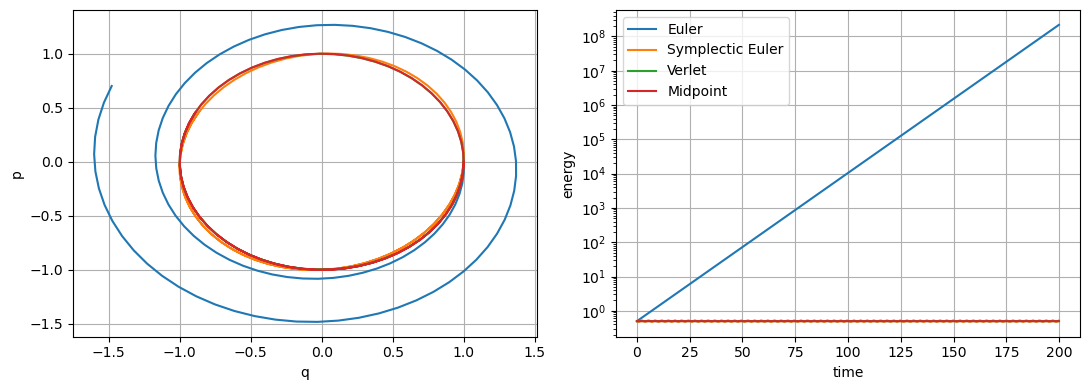

In [2]:
h=.1;N=2000
fig,ax=plt.subplots(1,2,figsize=(11,4))
for method in ["Euler","Symplectic Euler","Verlet","Midpoint"]:
 q,p=1.,0.;states=[]
 for _ in range(N):
  states.append((q,p))
  if method=="Euler": q,p=q+h*p,p-h*q
  elif method=="Symplectic Euler": p-=h*q;q+=h*p
  elif method=="Verlet": p-=h*q/2;q+=h*p;p-=h*q/2
  else:
   A=np.array([[0,1],[-1,0.]])
   q,p=np.linalg.solve(np.eye(2)-h*A/2,(np.eye(2)+h*A/2)@np.array([q,p]))
 states=np.array(states);energy=(states**2).sum(axis=1)/2
 ax[0].plot(states[:100,0],states[:100,1],label=method);ax[1].semilogy(np.arange(N)*h,energy,label=method)
 if method=="Midpoint": assert np.max(abs(energy-.5))<1e-10
ax[0].set(xlabel="q",ylabel="p");ax[1].set(xlabel="time",ylabel="energy");ax[1].legend();plt.tight_layout();plt.show()

## Read the result

Compare geometry, energy and phase separately. Bounded energy error does not imply exact phase or exact conservation. The nonlinear pendulum adds an amplitude-dependent period.

## Your turn

Replace the force -q with -sin(q) for Verlet. Use H=p²/2+1-cos(q), and compare two initial angles.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.